In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D  

sns.set_theme(style='whitegrid')
URL = 'https://raw.githubusercontent.com/PersDep/data-mining-intro-2021/main/hw03-EDA-data/german_credit.csv'
LOCAL = '../data/raw/german_credit.csv'

In [2]:
try:
    df = pd.read_csv(LOCAL)
except FileNotFoundError:
    df = pd.read_csv(URL)
print('Размер:', df.shape)
pd.concat([df.head(), df.tail()])

Размер: (1000, 21)


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,no checking account,18,all credits at this bank paid back duly,car (used),1049,unknown/no savings account,< 1 yr,< 20,female : non-single or male : single,none,...,car or other,21,none,for free,1,skilled employee/official,0 to 2,no,no,good
1,no checking account,9,all credits at this bank paid back duly,others,2799,unknown/no savings account,1 <= ... < 4 yrs,25 <= ... < 35,male : married/widowed,none,...,unknown / no property,36,none,for free,2-3,skilled employee/official,3 or more,no,no,good
2,... < 0 DM,12,no credits taken/all credits paid back duly,retraining,841,... < 100 DM,4 <= ... < 7 yrs,25 <= ... < 35,female : non-single or male : single,none,...,unknown / no property,23,none,for free,1,unskilled - resident,0 to 2,no,no,good
3,no checking account,12,all credits at this bank paid back duly,others,2122,unknown/no savings account,1 <= ... < 4 yrs,20 <= ... < 25,male : married/widowed,none,...,unknown / no property,39,none,for free,2-3,unskilled - resident,3 or more,no,yes,good
4,no checking account,12,all credits at this bank paid back duly,others,2171,unknown/no savings account,1 <= ... < 4 yrs,< 20,male : married/widowed,none,...,car or other,38,bank,rent,2-3,unskilled - resident,0 to 2,no,yes,good
995,no checking account,24,no credits taken/all credits paid back duly,furniture/equipment,1987,unknown/no savings account,1 <= ... < 4 yrs,25 <= ... < 35,male : married/widowed,none,...,unknown / no property,21,none,for free,1,unskilled - resident,3 or more,no,no,bad
996,no checking account,24,no credits taken/all credits paid back duly,others,2303,unknown/no savings account,>= 7 yrs,< 20,male : married/widowed,co-applicant,...,unknown / no property,45,none,rent,1,skilled employee/official,0 to 2,no,no,bad
997,... >= 200 DM / salary for at least 1 year,21,all credits at this bank paid back duly,others,12680,... >= 1000 DM,>= 7 yrs,< 20,male : married/widowed,none,...,real estate,30,none,own,1,manager/self-empl./highly qualif. employee,0 to 2,yes (under customer name),no,bad
998,... < 0 DM,12,no credits taken/all credits paid back duly,furniture/equipment,6468,... >= 1000 DM,unemployed,25 <= ... < 35,male : married/widowed,none,...,real estate,52,none,rent,1,manager/self-empl./highly qualif. employee,0 to 2,yes (under customer name),no,bad
999,no checking account,30,no credits taken/all credits paid back duly,car (used),6350,... >= 1000 DM,>= 7 yrs,< 20,male : married/widowed,none,...,car or other,31,none,rent,1,skilled employee/official,0 to 2,no,no,bad


In [3]:
print('Пропусков всего:', df.isna().sum().sum())
num_cols = df.select_dtypes('number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.drop('credit_risk').tolist()
print('Числовые:', num_cols)
print('Категориальные:', cat_cols)
print('Целевая переменная credit_risk:', df['credit_risk'].value_counts().to_dict())

Пропусков всего: 0
Числовые: ['duration', 'amount', 'age']
Категориальные: ['status', 'credit_history', 'purpose', 'savings', 'employment_duration', 'installment_rate', 'personal_status_sex', 'other_debtors', 'present_residence', 'property', 'other_installment_plans', 'housing', 'number_credits', 'job', 'people_liable', 'telephone', 'foreign_worker']
Целевая переменная credit_risk: {'good': 700, 'bad': 300}


In [4]:
df.groupby('purpose')['amount'].mean().sort_values(ascending=False).round(1)

purpose
business               8209.3
car (new)              5370.2
retraining             4158.0
repairs                3180.4
car (used)             3067.0
others                 3062.9
domestic appliances    2728.1
furniture/equipment    2487.7
radio/television       1498.0
vacation               1205.9
Name: amount, dtype: float64

In [6]:
young = df[df['age'] < 30]
middle = df[(df['age'] > 30) & (df['age'] < 40)]
old = df[df['age'] > 40]
print(f"Моложе 30: {(young['housing'] == 'rent').mean() * 100:.1f}% снимают жильё")
print(f"Старше 40: {(old['housing'] == 'rent').mean() * 100:.1f}% снимают жильё")
print(f"Старше 4: {(middle['housing'] == 'rent').mean() * 100:.1f}% снимают жильё")

Моложе 30: 66.7% снимают жильё
Старше 40: 68.0% снимают жильё
Старше 4: 78.8% снимают жильё


In [6]:
more_than_3 = df['number_credits'].isin(['4-5', '>= 6'])
print('Иностранцев с числом кредитов > 3:', ((df['foreign_worker'] == 'yes') & more_than_3).sum())

Иностранцев с числом кредитов > 3: 1


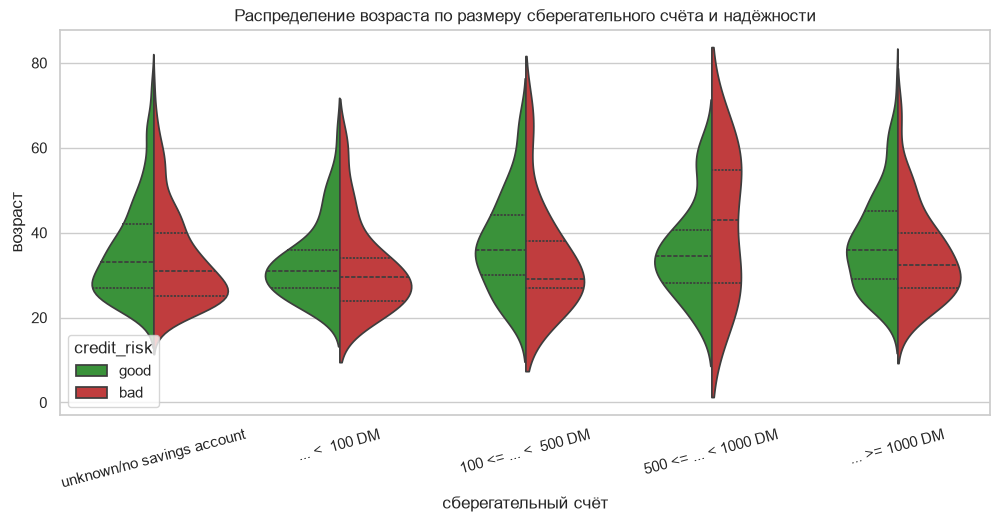

In [10]:
plt.figure(figsize=(12, 5))
sns.violinplot(data=df, x='savings', y='age', hue='credit_risk', order=savings_order,
               split=True, inner='quart', palette={'good': 'tab:green', 'bad': 'tab:red'})
plt.title('Распределение возраста по размеру сберегательного счёта и надёжности')
plt.xlabel('сберегательный счёт'); plt.ylabel('возраст')
plt.xticks(rotation=15); plt.show()

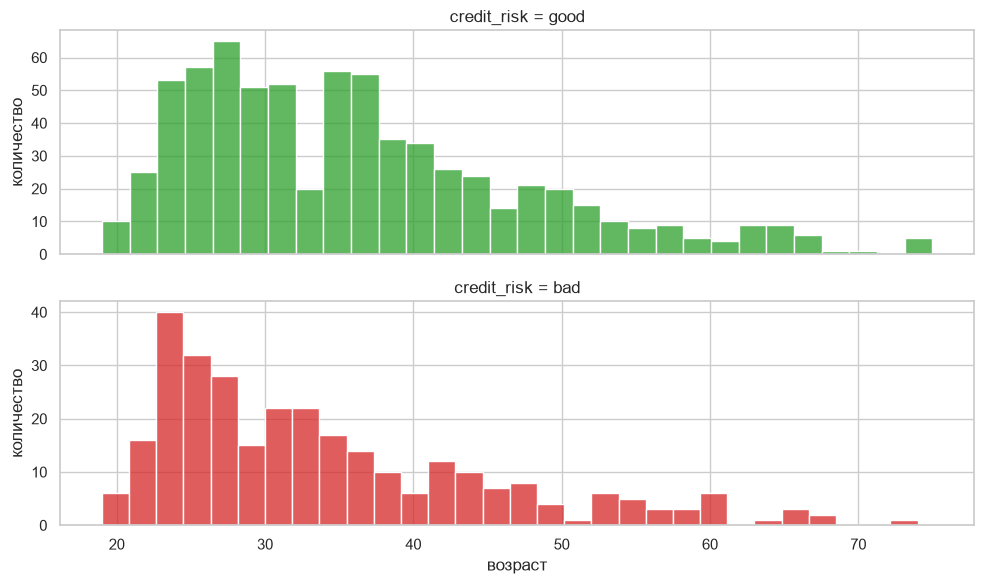

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, (risk, color) in zip(axes, [('good', 'tab:green'), ('bad', 'tab:red')]):
    sns.histplot(df.loc[df['credit_risk'] == risk, 'age'], bins=30, color=color, ax=ax)
    ax.set_title(f'credit_risk = {risk}'); ax.set_ylabel('количество')
axes[1].set_xlabel('возраст'); plt.tight_layout(); plt.show()

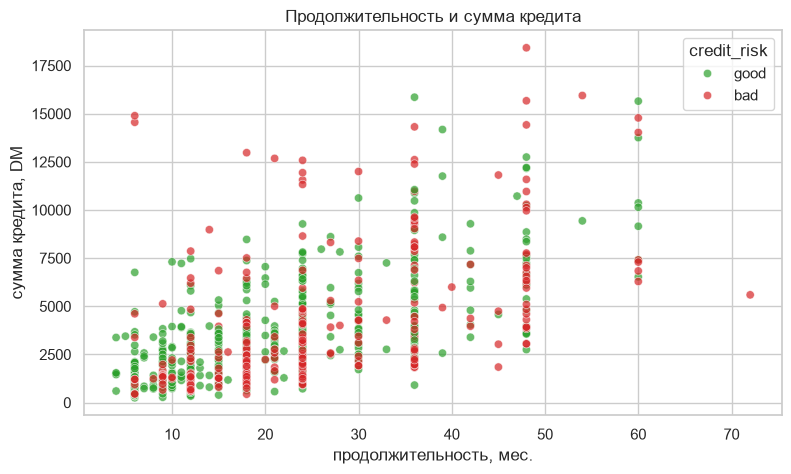

In [12]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='duration', y='amount', hue='credit_risk', alpha=0.7,
                palette={'good': 'tab:green', 'bad': 'tab:red'})
plt.title('Продолжительность и сумма кредита')
plt.xlabel('продолжительность, мес.'); plt.ylabel('сумма кредита, DM'); plt.show()

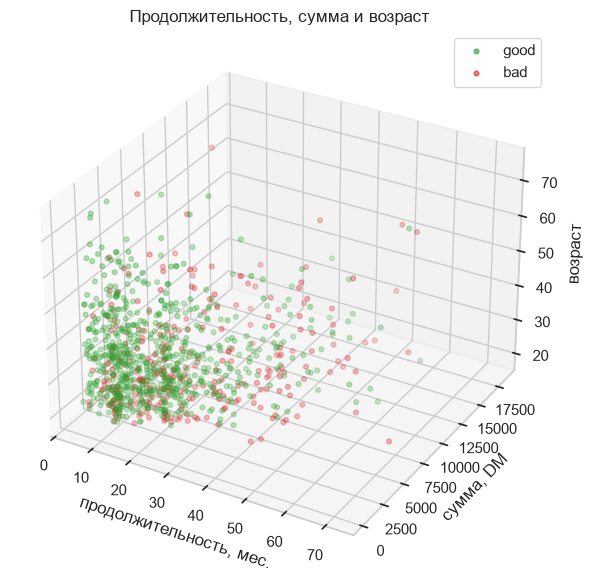

In [13]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection='3d')
for risk, color in [('good', 'tab:green'), ('bad', 'tab:red')]:
    part = df[df['credit_risk'] == risk]
    ax.scatter(part['duration'], part['amount'], part['age'], c=color, label=risk, alpha=0.6, s=12)
ax.set_xlabel('продолжительность, мес.'); ax.set_ylabel('сумма, DM'); ax.set_zlabel('возраст')
ax.set_title('Продолжительность, сумма и возраст'); ax.legend(); plt.show()

In [15]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(data))
train, test = data.iloc[idx[:700]].copy(), data.iloc[idx[700:]].copy()

for col in ['amount', 'duration', 'age']:
    edges = np.quantile(train[col], [0.2, 0.4, 0.6, 0.8])
    train[col] = np.digitize(train[col], edges)
    test[col] = np.digitize(test[col], edges)

features = data.columns.drop('credit_risk')
mu, sigma = train[features].mean(), train[features].std().replace(0, 1)
good, bad = train[train['credit_risk'] == 1], train[train['credit_risk'] == 0]
weights = (good[features].mean() - bad[features].mean()) / sigma
weights.sort_values()

duration              -0.363569
job                   -0.115909
amount                -0.084104
telephone              0.028897
present_residence      0.048935
people_liable          0.062197
number_credits         0.118608
foreign_worker         0.155245
installment_rate       0.167237
age                    0.249712
employment_duration    0.307995
savings                0.398139
status                 0.649755
dtype: float64

In [16]:
def score(X):
    """Условная оценка надёжности: взвешенная сумма стандартизованных признаков."""
    return ((X[features] - mu) / sigma) @ weights

# порог подбираем на train по максимуму точности
train_scores = score(train)
thresholds = np.quantile(train_scores, np.linspace(0.05, 0.95, 91))
train_acc = [((train_scores > t).astype(int) == train['credit_risk']).mean() for t in thresholds]
THRESHOLD = thresholds[int(np.argmax(train_acc))]

def predict(X):
    """Прогноз: 1 — надёжный клиент, 0 — ненадёжный."""
    return (score(X) > THRESHOLD).astype(int)

print(f'Порог: {THRESHOLD:.3f}')
print(f'Точность на train: {(predict(train) == train["credit_risk"]).mean():.3f}')
test_acc = (predict(test) == test['credit_risk']).mean()
print(f'Точность на test:  {test_acc:.3f}')
print(f'Базовая точность (всегда «good»): {test["credit_risk"].mean():.3f}')
assert test_acc >= 0.6

Порог: -1.398
Точность на train: 0.714
Точность на test:  0.773
Базовая точность (всегда «good»): 0.737
